<a href="https://colab.research.google.com/github/Hackathon-D-Group-2026/Hackathon_D_Group_2026/blob/main/pranay%20final%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NameError: name 'y_obs' is not defined

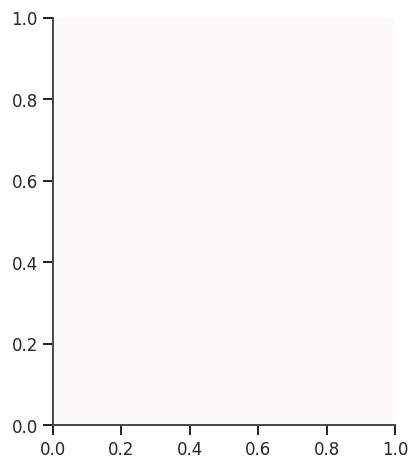

In [7]:
fig = plt.figure(figsize=(14, 4.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 2.2], wspace=0.28)

# Panel A: Horizontal stacked proportion bar + count callouts for target
ax0 = fig.add_subplot(gs[0])
p_acc = y_obs.mean()
p_dec = 1.0 - p_acc
ax0.barh(["Training\nCohort"], [p_acc * 100], color=THEME["teal"], height=0.42, label=f"Accepted (1): {y_obs.sum():,} ({p_acc:.1%})")
ax0.barh(["Training\nCohort"], [p_dec * 100], left=[p_acc * 100], color=THEME["crimson"], height=0.42, label=f"Declined (0): {(1-y_obs).sum():,} ({p_dec:.1%})")
ax0.text(p_acc * 50, 0, f"Accepted\n{p_acc:.1%}", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
ax0.text(p_acc * 100 + p_dec * 50, 0, f"Declined\n{p_dec:.1%}", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
ax0.set_xlim(0, 100)
ax0.set_xlabel("Percentage of Residents (%)")
ax0.set_title("II.1 Seasonal Flu Vaccine Uptake Split")
ax0.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False, fontsize=8.5)

# Panel B: Lollipop Stem Plot of Missingness (Train vs Test)
ax1 = fig.add_subplot(gs[1])
na_tr = train_data.drop(columns=[TARGET]).isna().mean() * 100
na_te = test_data.isna().mean() * 100
na_tbl = pd.DataFrame({"Train": na_tr, "Test": na_te}).query("Train > 0 or Test > 0").sort_values("Train")

y_idx = np.arange(len(na_tbl))
ax1.hlines(y=y_idx, xmin=0, xmax=na_tbl["Train"], color=THEME["slate"], alpha=0.5, lw=1.4)
ax1.scatter(na_tbl["Train"], y_idx, color=THEME["crimson"], s=45, label="Train % Missing", zorder=3)
ax1.scatter(na_tbl["Test"], y_idx, color=THEME["amber"], marker="D", s=32, label="Test % Missing", zorder=4)
ax1.set_yticks(y_idx, na_tbl.index, fontsize=8)
ax1.set_xlabel("Missing Entries (%)")
ax1.set_title("II.2 Lollipop Stem Plot of Missing Data (Train & Test Alignment)")
ax1.grid(axis="x")
ax1.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

NameError: name 'train_data' is not defined

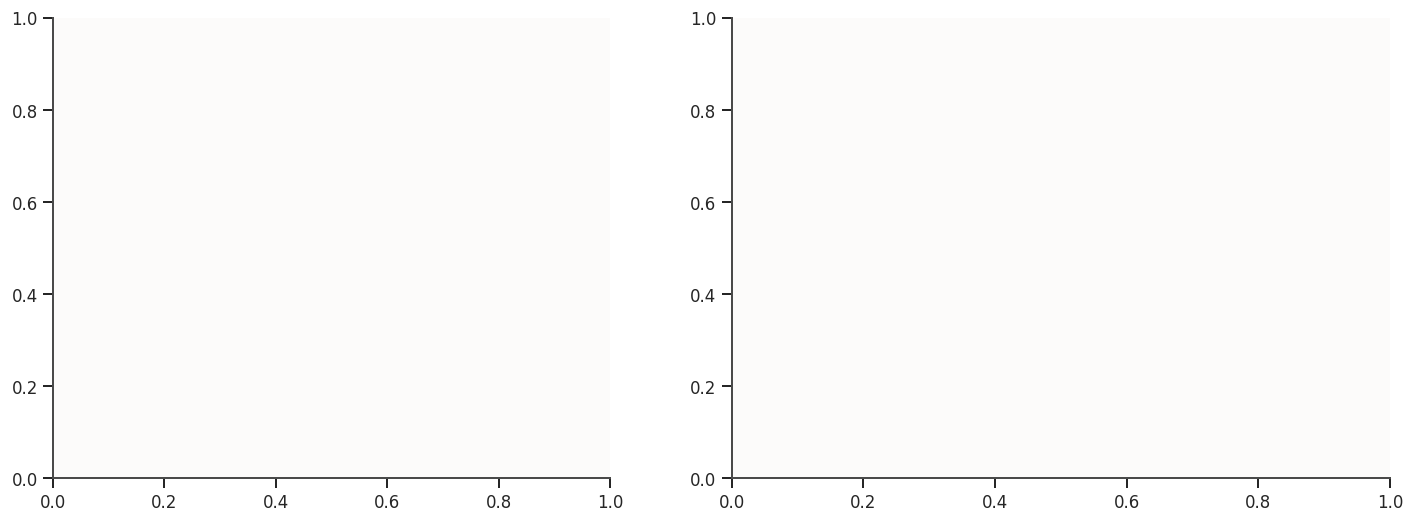

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.1, 1.3]})

# Left: Uptake trajectories across the three 1-to-5 Likert opinion scales
likert_cols = {
    "opinion_seas_vacc_effective": "Perceived Vaccine Effectiveness (1–5)",
    "opinion_seas_risk": "Perceived Flu Risk Without Vaccine (1–5)",
    "opinion_seas_sick_from_vacc": "Worry About Getting Sick From Vaccine (1–5)",
}
palette_lines = [THEME["teal"], THEME["crimson"], THEME["amber"]]
for (col, label), c_hex in zip(likert_cols.items(), palette_lines):
    sub = train_data[[col, TARGET]].dropna()
    grp = sub.groupby(col)[TARGET].agg(["mean", "count", "std"])
    se = grp["std"] / np.sqrt(grp["count"])
    axes[0].errorbar(grp.index, grp["mean"] * 100, yerr=1.96 * se * 100, marker="o", lw=2.2, capsize=4, label=label, color=c_hex)

axes[0].axhline(p_acc * 100, ls="--", color=THEME["slate"], lw=1, label=f"Population Mean ({p_acc:.1%})")
axes[0].set_xticks([1, 2, 3, 4, 5], ["1 (Very Low)", "2 (Low)", "3 (Neutral/DK)", "4 (High)", "5 (Very High)"], fontsize=8.5)
axes[0].set_ylabel("Seasonal Vaccine Uptake (%)")
axes[0].set_ylim(10, 90)
axes[0].set_title("II.3 Attitudinal Response Curves (Mean ± 95% CI)")
axes[0].grid(True)
axes[0].legend(fontsize=8, frameon=True, loc="upper left")

# Right: Cleveland Dot-and-CI Plot for Categorical / Binary Cohorts
cohorts = []
for feat, display_prefix in [
    ("doctor_recc_seasonal", "Doctor Recc"),
    ("health_worker", "Health Worker"),
    ("health_insurance", "Insurance"),
    ("age_group", "Age"),
    ("employment_status", "Employment"),
]:
    s = train_data[feat].fillna("Missing").astype(str).replace({"0.0": "No", "1.0": "Yes", "0": "No", "1": "Yes"})
    for val, grp_df in train_data.groupby(s):
        m = grp_df[TARGET].mean()
        n_g = len(grp_df)
        ci = 1.96 * np.sqrt(m * (1 - m) / max(n_g, 1))
        cohorts.append({"Group": f"{display_prefix}: {val}", "Uptake": m * 100, "CI": ci * 100, "N": n_g, "Category": display_prefix})

cohort_df = pd.DataFrame(cohorts).sort_values("Uptake")
y_pos = np.arange(len(cohort_df))
cat_color_map = {"Doctor Recc": THEME["crimson"], "Health Worker": THEME["amber"], "Insurance": THEME["plum"], "Age": THEME["teal"], "Employment": THEME["slate"]}
c_vec = [cat_color_map[c] for c in cohort_df["Category"]]

axes[1].errorbar(cohort_df["Uptake"], y_pos, xerr=cohort_df["CI"], fmt="none", ecolor=THEME["slate"], elinewidth=1.2, capsize=2.5, zorder=2)
axes[1].scatter(cohort_df["Uptake"], y_pos, c=c_vec, s=48, zorder=3)
axes[1].axvline(p_acc * 100, ls="--", color="black", lw=0.9)
axes[1].set_yticks(y_pos, cohort_df["Group"], fontsize=8)
axes[1].set_xlabel("Seasonal Vaccine Uptake (%) with 95% CI")
axes[1].set_title("II.4 Cleveland Dot Plot of Uptake Across Key Cohorts")
axes[1].grid(axis="x")

plt.tight_layout()
plt.show()